# Figure S6 — short test

BANC-DN/motor fixed-input message substitution and closed-loop recovery.

The saved tables and figures below come from a real short test and can be viewed directly on GitHub. To regenerate them, use the **Python (FlyControl)** kernel; see [setup and notebook index](README.md). Run cells from top to bottom. This notebook executes the same six stages as the command-line workflow, with reduced budgets and one training seed. It keeps every configured method. **These are software checks, not paper results.**

First execution downloads versioned public inputs. Neural assays and multi-stage maze prerequisites can still take substantial time; “short” refers to the training budget, not a seconds-long demonstration. Generated checkpoints, data and figures stay under `runs/`.

Choose a fresh `RUN_DIR` after code/configuration changes or for an independent restart. A completed run can be inspected with the “Inspect the smoke outputs” cell without retraining.

## Settings

Launch Jupyter from the repository root or `notebooks/`. Select the installed FlyControl kernel before running.

`DEVICE` defaults to CPU. To use a GPU, set it to an available device (for example `cuda:0`) or launch Jupyter with `FLYCONTROL_NOTEBOOK_DEVICE=cuda:0`. The saved execution records the device actually used.

In [1]:
from pathlib import Path
import sys
import os

ROOT = next(
    path for path in (Path.cwd(), *Path.cwd().parents)
    if (path / "pyproject.toml").is_file()
    and (path / "src/flycontrol").is_dir()
)
sys.path.insert(0, str(ROOT / "notebooks"))
from notebook_utils import run_stage, show_outputs

CONFIG = 'banc-recovery'
RUN_DIR = ROOT / "runs/notebooks" / CONFIG
DEVICE = os.environ.get("FLYCONTROL_NOTEBOOK_DEVICE", "cpu")
WORKERS = 1
print(f"SMOKE TEST: {CONFIG} | {DEVICE} | {RUN_DIR.relative_to(ROOT)}")


SMOKE TEST: banc-recovery | cuda:0 | runs/notebooks/banc-recovery


## 1. Prepare

Download and checksum-verify public inputs, then resolve the reduced configuration. This cell always sets `--smoke`; all configured methods and the first training seed are retained.

In [2]:
run_stage("prepare", CONFIG, RUN_DIR, DEVICE, WORKERS)

**Completed: prepare** · 29.4 seconds · smoke test

Full execution log: `logs/notebook-prepare.log` within the run directory.

## 2. Train

Train fresh policies using the reduced budgets. This includes any prerequisites required by the selected experiment.

In [3]:
run_stage("train", CONFIG, RUN_DIR, DEVICE, WORKERS)

**Completed: train** · 63.4 seconds · smoke test

Full execution log: `logs/notebook-train.log` within the run directory.

## 3. Evaluate

Run the configured smoke evaluations in the real simulator, recording failures as well as successful episodes.

In [4]:
run_stage("evaluate", CONFIG, RUN_DIR, DEVICE, WORKERS)

**Completed: evaluate** · 566.2 seconds · smoke test

Full execution log: `logs/notebook-evaluate.log` within the run directory.

## 4. Probe

Run the configured neural assays. Experiments without a neural assay record that explicitly. Short-trained policies can fail the required histories; read the recorded exclusions.

In [5]:
run_stage("probe", CONFIG, RUN_DIR, DEVICE, WORKERS)

**Completed: probe** · 24.8 seconds · smoke test

Full execution log: `logs/notebook-probe.log` within the run directory.

## 5. Analyze

Aggregate the generated numerical records. Smoke outputs do not support the manuscript’s statistical conclusions.

In [6]:
run_stage("analyze", CONFIG, RUN_DIR, DEVICE, WORKERS)

**Completed: analyze** · 1.5 seconds · smoke test

Full execution log: `logs/notebook-analyze.log` within the run directory.

## 6. Plot

Create diagnostic panels, numerical sources and editable PDF/SVG figures from this run.

In [7]:
run_stage("plot", CONFIG, RUN_DIR, DEVICE, WORKERS)

**Completed: plot** · 9.3 seconds · smoke test

Full execution log: `logs/notebook-plot.log` within the run directory.

## Inspect the smoke outputs

Check completion and effective settings, then inspect sample tables and up to three generated figures. All files remain available in `RUN_DIR`.

**SMOKE TEST — not paper results.**

,experiment,methods,training seeds
0,banc-recovery,"banc_motor, banc_descending",[0]


Source/configuration SHA-256: `eaab77b7c7f8b5c50e7015c4c1c15e9ce272e2e432760c88fcc2e24c7a48ea9f`

,stage,completed,elapsed seconds
0,prepare,True,29.40
1,train,True,63.45
2,evaluate,True,566.21
3,probe,True,24.79
4,analyze,True,1.50
5,plot,True,9.33


`analysis/regional_seed_effects.csv` (first eight rows)

...

`analysis/regional_episodes.csv` (first eight rows)

,signed_force,intervention,onset_s,window_s,duration_s,auc_observed,auc_missing_penalty,auc,missing_duration_s,flipped,...,tilt_auc,max_tilt_rad,raw_auc_error,forward_command_mean,turn_command_mean,forward_command_saturation,turn_command_saturation,complete_pulse,replayed_edge_count,fractional_abs_weight_sum
0,0.0,intact,0.75,0.5,0.5,0.065730,0.0,0.065730,0.0,False,...,0.398429,0.892797,0.000000e+00,-0.013609,-0.001041,0.0,0.0,True,NaN,NaN
1,-10.0,intact,0.75,0.5,0.5,0.064110,0.0,0.064110,0.0,False,...,0.394718,0.924608,1.387779e-17,-0.014052,-0.001092,0.0,0.0,True,NaN,NaN
2,10.0,intact,0.75,0.5,0.5,0.071609,0.0,0.071609,0.0,False,...,0.401098,0.958964,1.387779e-17,-0.013633,-0.001206,0.0,0.0,True,NaN,NaN
3,10.0,vnc_reference,0.75,0.5,0.5,0.039864,0.0,0.039864,0.0,False,...,0.403953,0.958964,6.938894e-18,-0.013560,-0.000905,0.0,0.0,True,871868.0,22952.046875
4,-10.0,an_brain_reference,0.75,0.5,0.5,0.079124,0.0,0.079124,0.0,False,...,0.395122,0.920303,2.775558e-17,-0.014115,-0.000948,0.0,0.0,True,70579.0,772.588318
5,-10.0,replay_all_observations,0.75,0.5,0.5,0.094646,0.0,0.094646,0.0,False,...,0.397855,0.921509,1.387779e-17,-0.013609,-0.001041,0.0,0.0,True,0.0,0.000000
6,10.0,brain_reference,0.75,0.5,0.5,0.048814,0.0,0.048814,0.0,False,...,0.405124,0.958964,1.387779e-17,-0.013651,-0.001143,0.0,0.0,True,1811108.0,84079.789062
7,0.0,vnc_reference,0.75,0.5,0.5,0.065730,0.0,0.065730,0.0,False,...,0.398429,0.892797,0.000000e+00,-0.013609,-0.001041,0.0,0.0,True,871868.0,22952.046875


`analysis/regional_factorial_interactions.csv` (first eight rows)

,condition,n_models,delta_auc_mean,delta_auc_lo,delta_auc_hi,delta_success_mean,delta_success_lo,delta_success_hi,delta_flipped_mean,delta_flipped_lo,...,delta_heading_only_failure_hi,delta_sustained_success_last100ms_mean,delta_sustained_success_last100ms_lo,delta_sustained_success_last100ms_hi,delta_tilt_auc_mean,delta_tilt_auc_lo,delta_tilt_auc_hi,delta_max_tilt_rad_mean,delta_max_tilt_rad_lo,delta_max_tilt_rad_hi
0,banc_descending,1,0.008381,0.008381,0.008381,0.5,0.5,0.5,0.0,0.0,...,-0.5,-0.5,-0.5,-0.5,-0.006389,-0.006389,-0.006389,0.002525,0.002525,0.002525
1,banc_motor,1,-0.029455,-0.029455,-0.029455,0.0,0.0,0.0,0.0,0.0,...,0.0,0.5,0.5,0.5,0.000387,0.000387,0.000387,-0.002883,-0.002883,-0.002883


`figures/paper/S6_delta_auc.png`

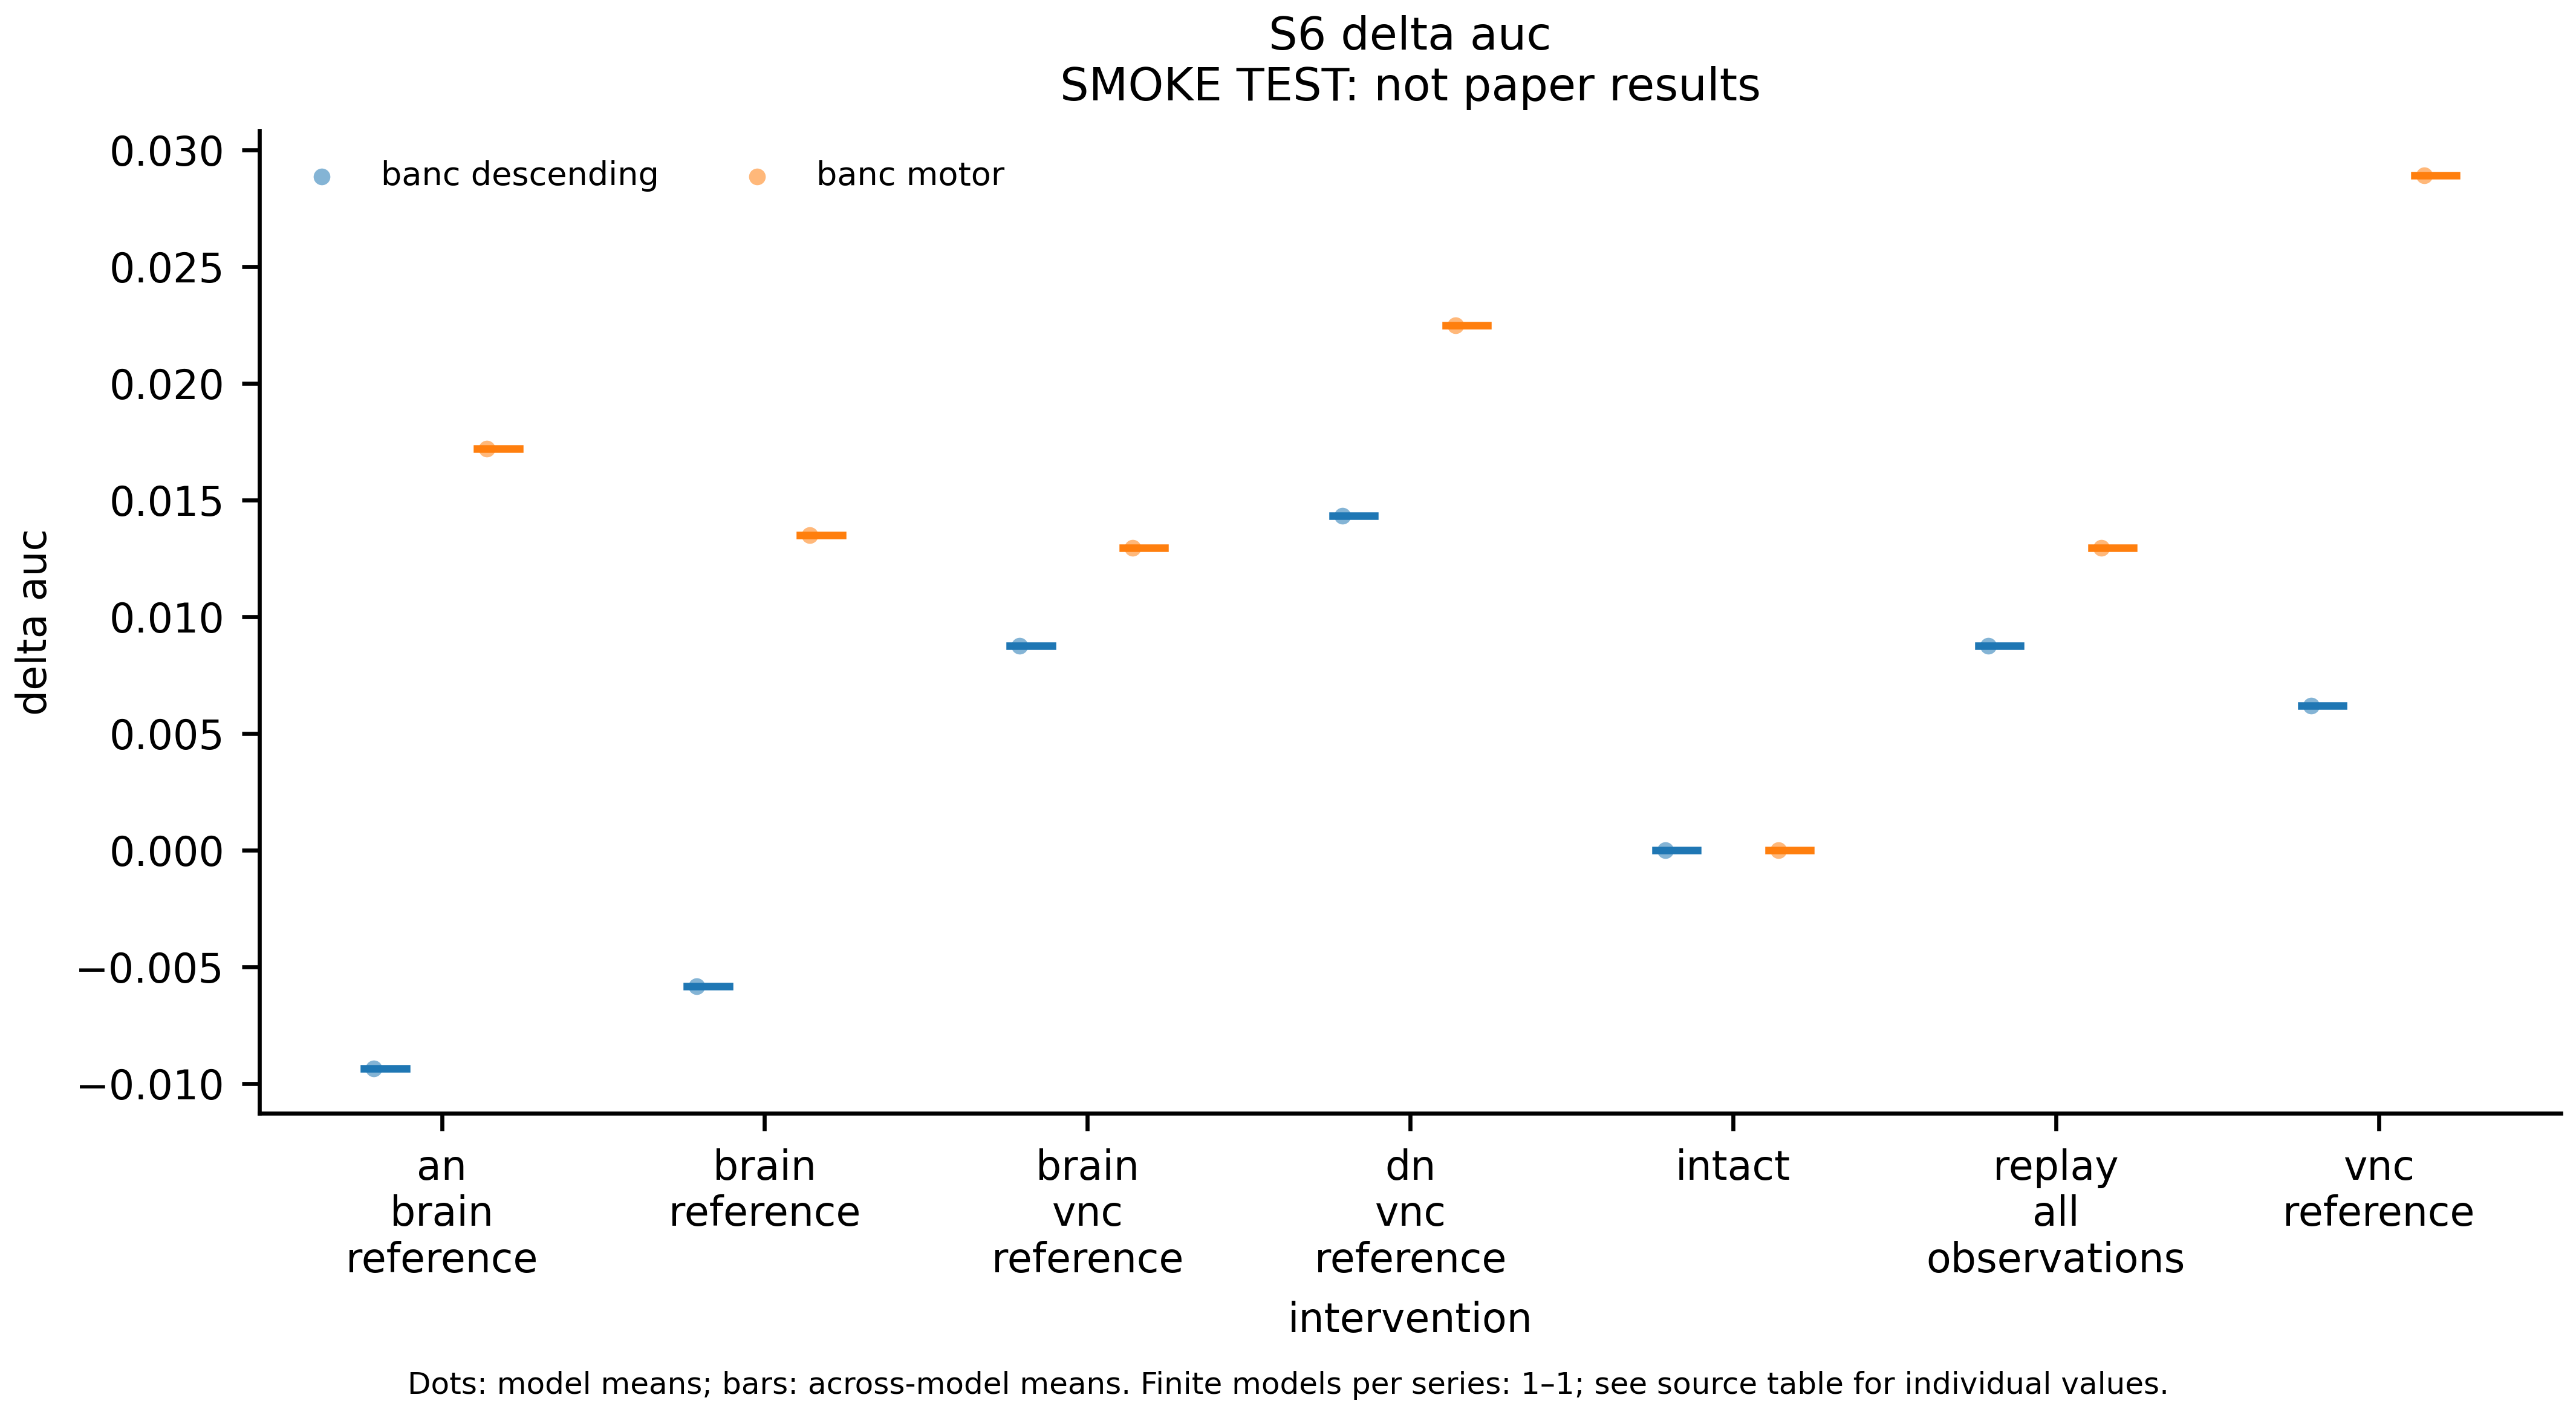

`figures/paper/S6_delta_flipped.png`

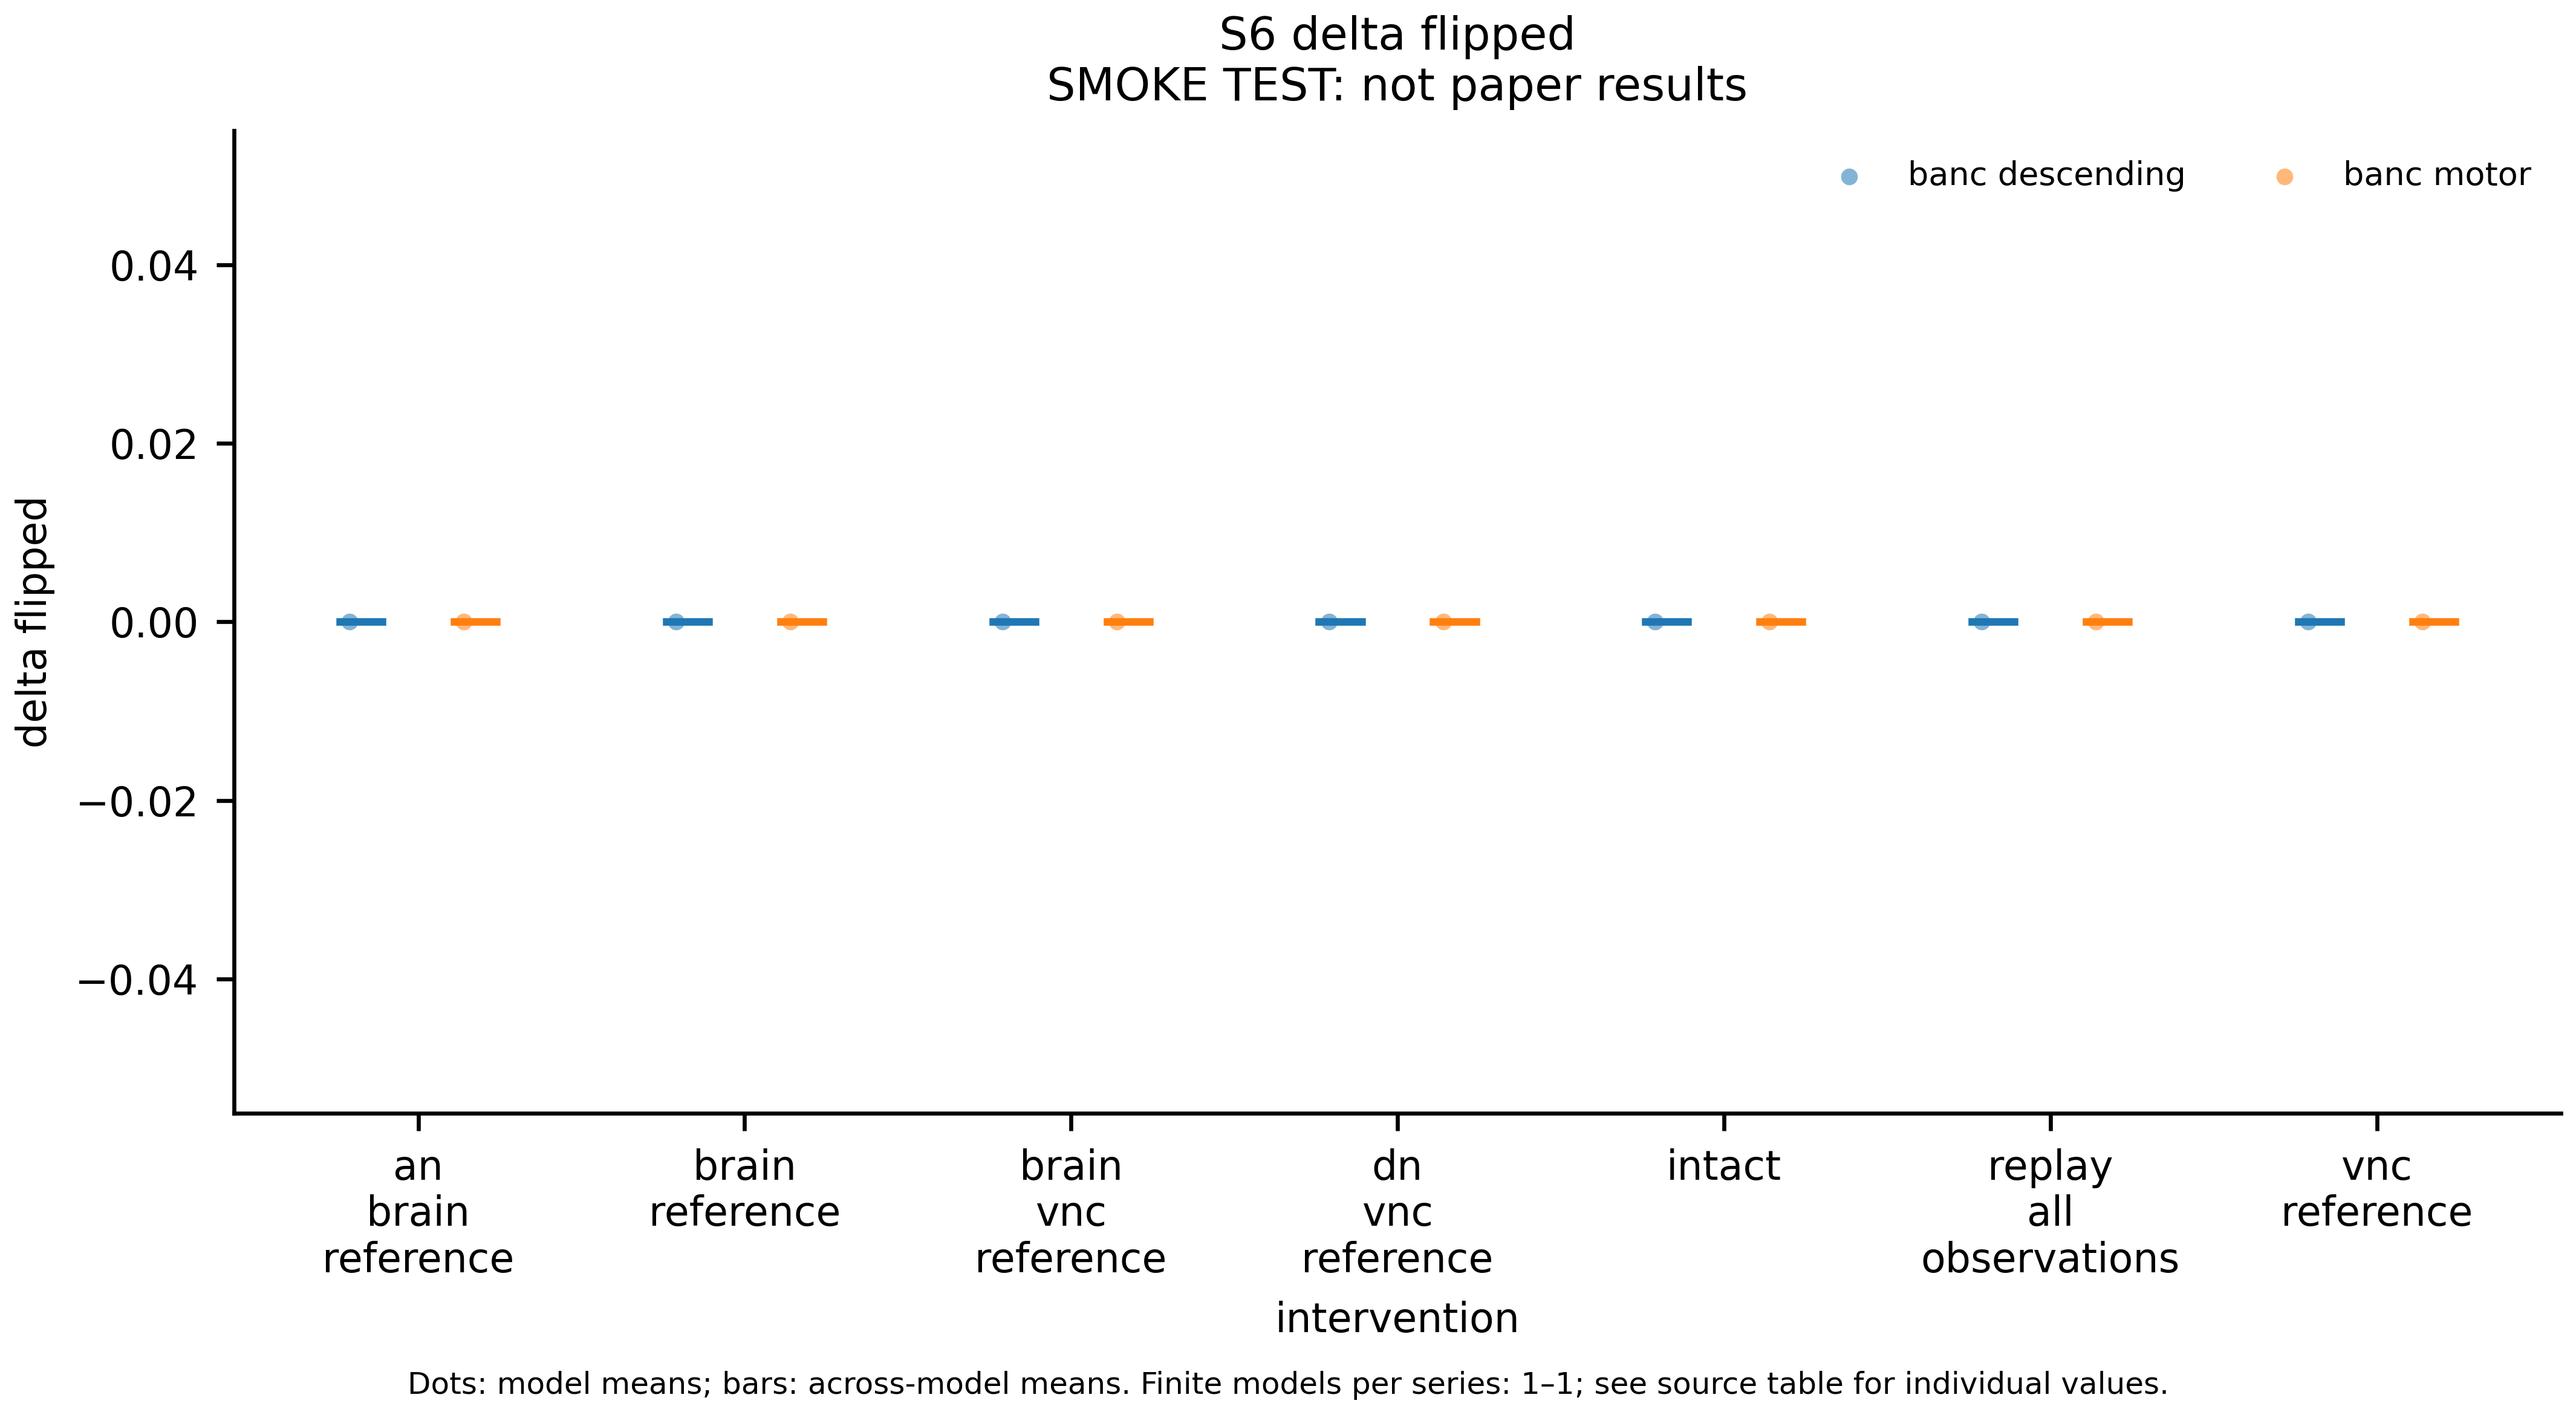

`figures/paper/S6_delta_success.png`

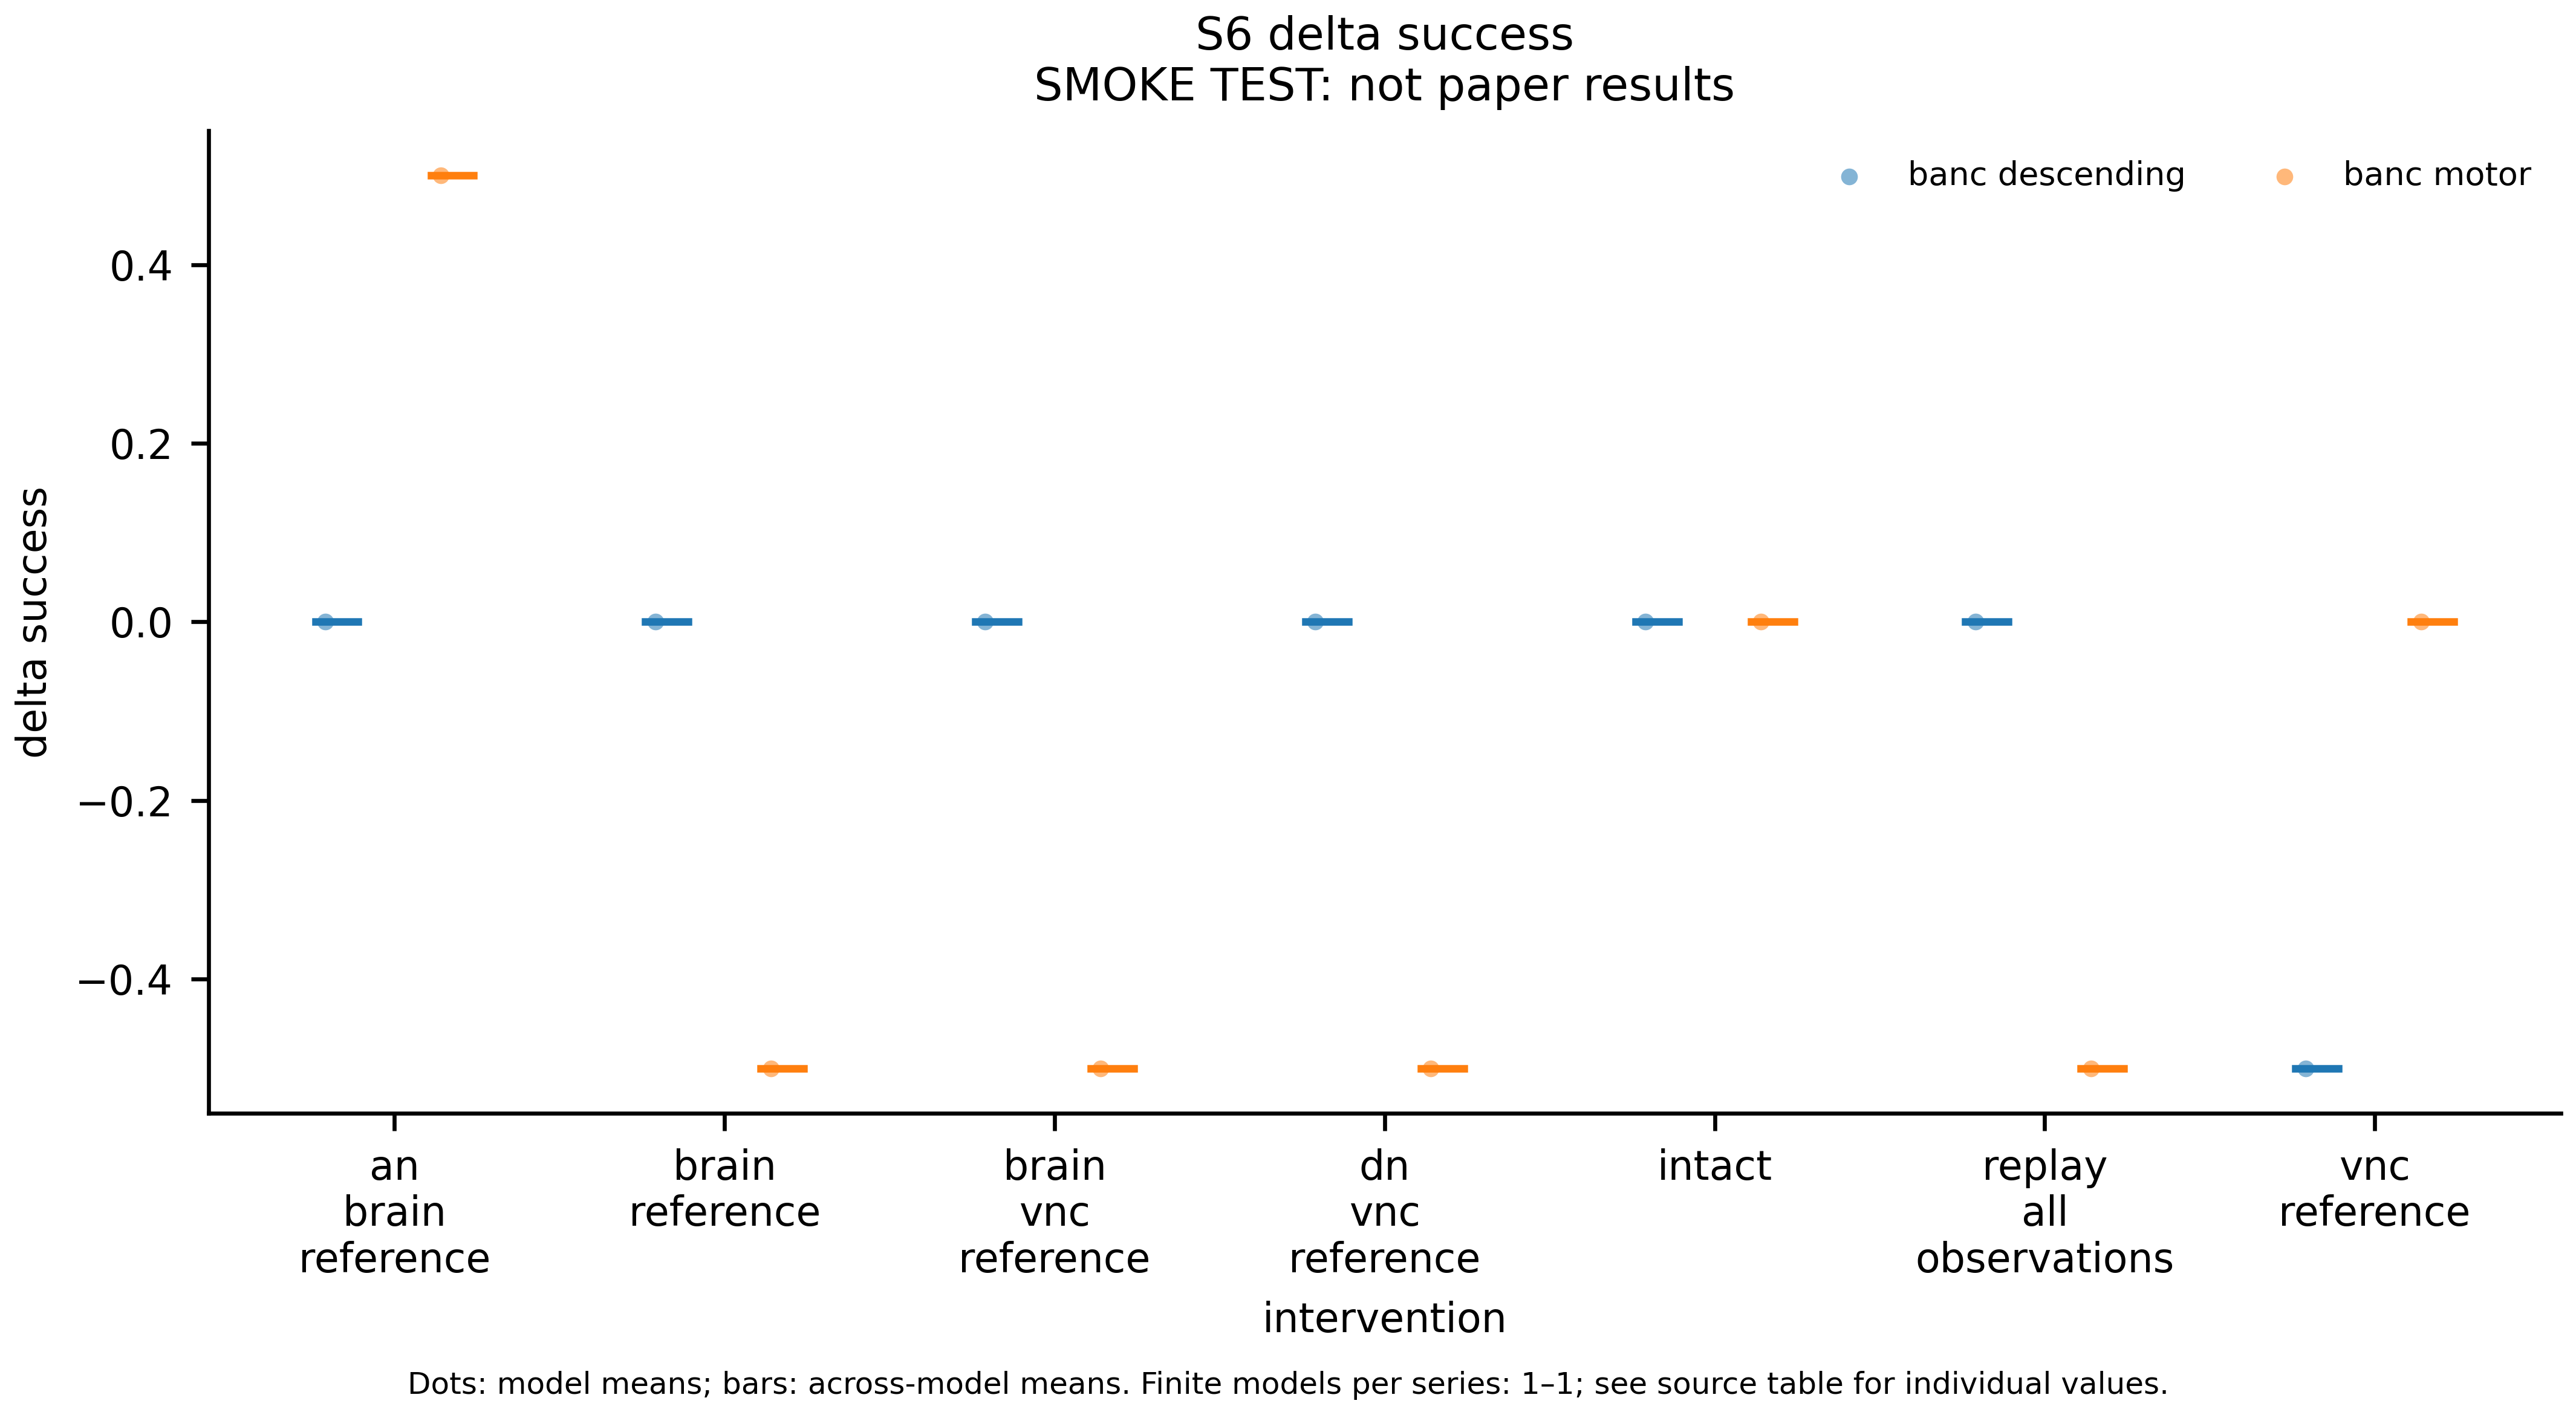

The complete numerical files and figures are saved in `RUN_DIR`. The tables and images displayed here are embedded in this notebook.

In [8]:
show_outputs(RUN_DIR)

## Full reproduction

Run this command in a terminal from the repository root, with the environment activated:

```bash
python scripts/S06_banc_recovery.py --run-dir runs/banc-recovery --device cuda:0 --workers 4
```

Equivalent command:

```bash
flycontrol run --config banc-recovery --run-dir runs/banc-recovery --device cuda:0 --workers 4
```

Use an available CUDA device, or `cpu`. Without `--smoke`, the script uses the complete fixed seed cohort, training budgets and condition grids. Keep full outputs in a separate run directory. These commands are documentation only; **Run All never launches the full campaign**.
